Renamed 'fbs' column to 'target' to use as the binary label.
Columns present in dataset: ['age', 'sex', 'cp', 'trestbps', 'chol', 'target']
Shape of dataset: (606, 6)
<class 'pandas.core.frame.DataFrame'>
Index: 606 entries, 0 to 882
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       606 non-null    int64  
 1   sex       606 non-null    int64  
 2   cp        606 non-null    int64  
 3   trestbps  606 non-null    float64
 4   chol      606 non-null    int64  
 5   target    606 non-null    int64  
dtypes: float64(1), int64(5)
memory usage: 33.1 KB


,age,sex,cp,trestbps,chol,target
count,606.000000,606.000000,606.000000,606.000000,606.000000,606.000000
mean,27.447195,75.165017,0.646865,66.331683,123.831683,0.285479
std,27.697475,76.280490,0.862850,66.515517,127.889162,0.452015
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,0.000000,0.800000,1.000000,0.000000
50%,15.500000,36.000000,0.000000,50.100000,64.000000,0.000000
75%,55.000000,152.750000,1.000000,130.000000,240.000000,1.000000
max,77.000000,202.000000,3.000000,200.000000,564.000000,1.000000


Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
target      0
dtype: int64
target
0    433
1    173
Name: count, dtype: int64


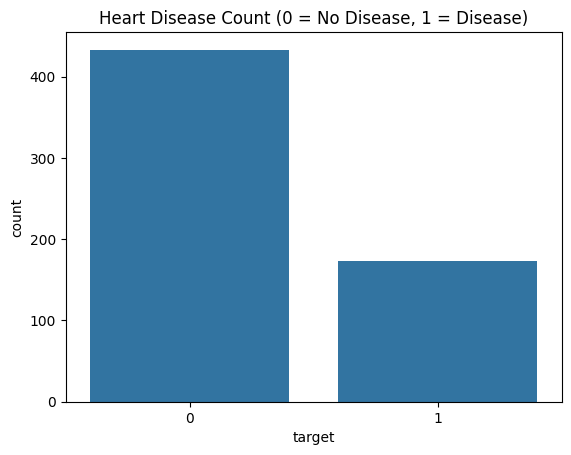

Training data size: (484, 5)
Testing data size: (122, 5)
Training model 1
Training model 2
Training model 3
All models trained successfully
Model 1 Accuracy: 0.7459016393442623


Model 2 Accuracy: 0.7868852459016393
Model 3 Accuracy: 0.7377049180327869
Ensemble Model Accuracy: 0.7459016393442623
Model 1 : 74.59 %
Model 2 : 78.69 %
Model 3 : 73.77 %
Ensemble (Average) : 74.59 %


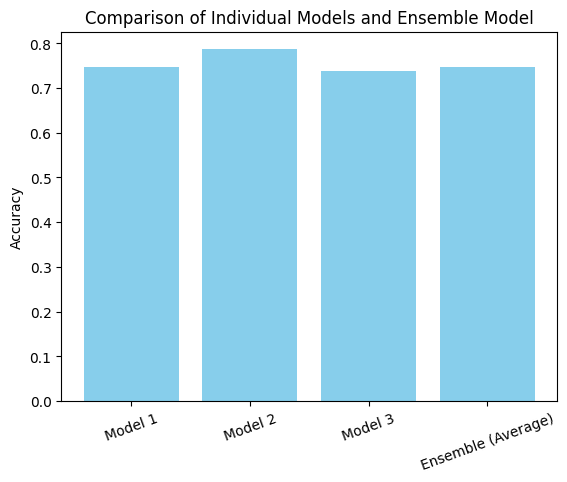

Confusion Matrix:
[[83 11]
 [20  8]]
Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.88      0.84        94
           1       0.42      0.29      0.34        28

    accuracy                           0.75       122
   macro avg       0.61      0.58      0.59       122
weighted avg       0.72      0.75      0.73       122



In [4]:
# import basic libraries for data handling
import pandas as pd
import numpy as np
# import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns
# import libraries for model building
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# import tensorflow and keras for building neural network models
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
# set random seed so results stay same on every run
tf.random.set_seed(42)
np.random.seed(42)

# load heart disease dataset (UCI heart disease dataset)
data = pd.read_csv("heart.csv")

# Clean up any trailing empty rows (where all or most values are NaN)
data = data.dropna(thresh=3)

# Rename 'fbs' to 'target' if 'target' does not exist but 'fbs' does
if 'target' not in data.columns and 'fbs' in data.columns:
    data = data.rename(columns={'fbs': 'target'})
    print("Renamed 'fbs' column to 'target' to use as the binary label.")

# Let's inspect the columns
print("Columns present in dataset:", data.columns.tolist())

# Verification check
if 'target' not in data.columns:
    print("WARNING: 'target' column not found. Please rename your label column to 'target'.")
    print("Current columns available:", data.columns.tolist())
else:
    # Clean target values to ensure binary classification format (0 or 1)
    # Convert target to numeric, coerce errors, and fill NaN values if any
    data['target'] = pd.to_numeric(data['target'], errors='coerce')
    data = data.dropna(subset=['target'])
    data['target'] = (data['target'] > 0).astype(int)

    # Ensure other features are numeric for scaling and neural networks
    for col in data.columns:
        if col != 'target':
            data[col] = pd.to_numeric(data[col], errors='coerce')
    data = data.dropna()

    # check shape of dataset (rows, columns)
    print("Shape of dataset:", data.shape)
    # check basic info of dataset
    data.info()

    # check statistical summary of the dataset
    display(data.describe())

    # check if any missing values are present
    print("Missing values:\n", data.isnull().sum())

    # check how many patients have heart disease (1) and how many do not (0)
    print(data['target'].value_counts())

    # plot count of patients with and without heart disease
    sns.countplot(x='target', data=data)
    plt.title("Heart Disease Count (0 = No Disease, 1 = Disease)")
    plt.show()

    # X contains all input features, y contains the target column
    X = data.drop('target', axis=1)
    y = data['target']

    # split data into 80% training and 20% testing
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    print("Training data size:", X_train.shape)
    print("Testing data size:", X_test.shape)

    # scale the features so all values are on same range
    # neural networks train better when input values are scaled
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # function to build one neural network model
    def build_model(units1, units2, seed):
        # set seed so every model starts a bit different from others
        tf.random.set_seed(seed)
        model = keras.Sequential([
            layers.Input(shape=(X_train.shape[1],)),
            layers.Dense(units1, activation='relu'),
            layers.Dense(units2, activation='relu'),
            layers.Dense(1, activation='sigmoid') # sigmoid gives output between 0 and 1
        ])
        # compile model with loss function and optimizer
        model.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])
        return model

    # list to store all trained models
    models = []

    # settings for 3 different models (different hidden layer sizes and seeds)
    model_settings = [
        {"units1": 16, "units2": 8, "seed": 1},
        {"units1": 32, "units2": 16, "seed": 2},
        {"units1": 8, "units2": 8, "seed": 3}
    ]
    # train each model one by one
    for i, setting in enumerate(model_settings):
        print("Training model", i + 1)
        model = build_model(setting["units1"], setting["units2"], setting["seed"])
        # train the model on training data
        model.fit(X_train, y_train, epochs=50, batch_size=16, verbose=0)
        # save trained model in the list
        models.append(model)
    print("All models trained successfully")

    # check accuracy of every model separately on test data
    individual_accuracies = []
    for i, model in enumerate(models):
        # get probability predictions and convert to 0 or 1
        pred_prob = model.predict(X_test, verbose=0)
        pred_label = (pred_prob > 0.5).astype(int).flatten()
        acc = accuracy_score(y_test, pred_label)
        individual_accuracies.append(acc)
        print("Model", i + 1, "Accuracy:", acc)

    # get predictions from every model
    all_predictions = []
    for model in models:
        pred_prob = model.predict(X_test, verbose=0)
        all_predictions.append(pred_prob)
    # convert list to numpy array for easy averaging
    all_predictions = np.array(all_predictions)
    # take average of predictions from all models
    ensemble_prob = np.mean(all_predictions, axis=0)
    # convert average probability into final class (0 or 1)
    ensemble_pred = (ensemble_prob > 0.5).astype(int).flatten()

    # calculate accuracy of the combined ensemble model
    ensemble_acc = accuracy_score(y_test, ensemble_pred)
    print("Ensemble Model Accuracy:", ensemble_acc)

    # store results in a dictionary for comparison
    results = {}
    for i, acc in enumerate(individual_accuracies):
        results["Model " + str(i + 1)] = acc
    results["Ensemble (Average)"] = ensemble_acc
    # print comparison table
    for name, acc in results.items():
        print(name, ":", round(acc * 100, 2), "%")

    # plot bar chart to compare accuracy of all models
    plt.bar(results.keys(), results.values(), color='skyblue')
    plt.ylabel("Accuracy")
    plt.title("Comparison of Individual Models and Ensemble Model")
    plt.xticks(rotation=20)
    plt.show()

    # print confusion matrix for the ensemble model
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, ensemble_pred))
    # print classification report for the ensemble model
    print("Classification Report:")
    print(classification_report(y_test, ensemble_pred))